## Analisis de los datos de la premier del año 2025/2026


* ¿Existe ventaja estadística de jugar como local?
* ¿Qué equipos tienen el mejor rendimiento ofensivo y defensivo?
* ¿Qué relación existe entre el resultado del primer tiempo y el resultado final?
* ¿Qué equipos generan más partidos con muchos goles?
* ¿Qué tan frecuentes son las victorias locales, empates y victorias visitantes?
* ¿Cómo varía la cantidad de goles a lo largo de la temporada?
* ¿Existe relación entre las cuotas de las casas de apuestas y el resultado real del partido?

In [9]:
# obtenemos los datos de la web: Website: https://www.football-data.co.uk/data.php
import pandas as pd
premier_2526 = pd.read_csv("https://football-data.co.uk/mmz4281/2526/E0.csv")
premier_2526.head()

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,E0,15/08/2025,20:00,Liverpool,Bournemouth,4,2,H,1,0,...,2.03,1.78,2.07,1.85,2.03,1.88,1.94,1.76,2.14,1.86
1,E0,16/08/2025,12:30,Aston Villa,Newcastle,0,0,D,0,0,...,2.05,1.80,2.02,1.89,2.06,1.80,1.95,1.74,2.14,1.86
2,E0,16/08/2025,15:00,Brighton,Fulham,1,1,D,0,0,...,1.83,2.03,1.93,2.00,1.84,2.03,1.80,1.96,1.91,2.08
3,E0,16/08/2025,15:00,Sunderland,West Ham,3,0,H,0,0,...,1.95,1.90,1.97,1.95,1.95,1.94,1.86,1.78,2.02,1.97
4,E0,16/08/2025,15:00,Tottenham,Burnley,3,0,H,1,0,...,1.98,1.88,1.99,1.93,1.98,1.91,1.88,1.83,2.07,1.92


In [19]:
# cambiamos de nombre a algunas columnas para que sean más fáciles de manejar
premier_2526.rename(columns={
    "Date":"Fecha",
    "Time":"Hora",
    "HomeTeam":"Equipo_Local",
    "HomeTeam":"Equipo_Local",
    "AwayTeam":"Equipo_Visitante",
    "FTGH":"Goles_Local",
    "FTGA":"Goles_Visitante",}, inplace=True)
premier_2526.head()

,Div,Fecha,Hora,Equipo_Local,Equipo_Visitante,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,E0,15/08/2025,20:00,Liverpool,Bournemouth,4,2,H,1,0,...,2.03,1.78,2.07,1.85,2.03,1.88,1.94,1.76,2.14,1.86
1,E0,16/08/2025,12:30,Aston Villa,Newcastle,0,0,D,0,0,...,2.05,1.80,2.02,1.89,2.06,1.80,1.95,1.74,2.14,1.86
2,E0,16/08/2025,15:00,Brighton,Fulham,1,1,D,0,0,...,1.83,2.03,1.93,2.00,1.84,2.03,1.80,1.96,1.91,2.08
3,E0,16/08/2025,15:00,Sunderland,West Ham,3,0,H,0,0,...,1.95,1.90,1.97,1.95,1.95,1.94,1.86,1.78,2.02,1.97
4,E0,16/08/2025,15:00,Tottenham,Burnley,3,0,H,1,0,...,1.98,1.88,1.99,1.93,1.98,1.91,1.88,1.83,2.07,1.92


### ¿Existe ventaja estadística de jugar como local?

In [21]:
premier_2526["FTR"].value_counts()

FTR
H    162
A    114
D    104
Name: count, dtype: int64

In [25]:
resultados = premier_2526["FTR"].value_counts()

porcentajes = premier_2526["FTR"].value_counts(normalize=True) * 100

print("Victoria local:", porcentajes.get("H", 0))
print("Empate:", porcentajes.get("D", 0))
print("Victoria visitante:", porcentajes.get("A", 0))

Victoria local: 42.63157894736842
Empate: 27.368421052631582
Victoria visitante: 30.0


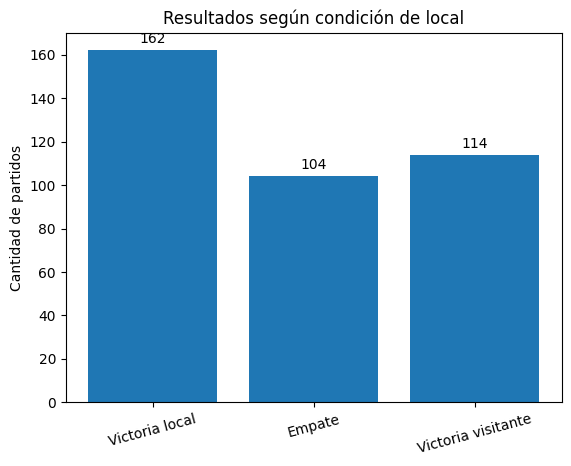

In [ ]:
import matplotlib.pyplot as plt

etiquetas = ["Victoria local", "Empate", "Victoria visitante"]

valores = [
    resultados.get("H", 0),
    resultados.get("D", 0),
    resultados.get("A", 0)]

fig, ax = plt.subplots()
barras = ax.bar(etiquetas, valores)
ax.bar_label(barras, padding=3)

ax.set_title("Resultados según condición de local")
ax.set_ylabel("Cantidad de partidos")
plt.xticks(rotation=15)

plt.show()

In [35]:
# porcentaje de ventaja jugando de local
porcentaje_l = porcentajes.get("H", 0)
porcentaje_v = porcentajes.get("A", 0)
ventaja_l = porcentaje_l - porcentaje_v

print("Porcentaje de victorias locales:", round(porcentaje_l, 2), "%")
print("Porcentaje de victorias visitantes:", round(porcentaje_v, 2), "%")
print("---"*15)
print("Ventaja de jugar como local:", round(ventaja_l, 2), "prociento")
print("---"*15)

Porcentaje de victorias locales: 42.63 %
Porcentaje de victorias visitantes: 30.0 %
---------------------------------------------
Ventaja de jugar como local: 12.63 prociento
---------------------------------------------


### Conclución
Existe una ventaja estadística de jugar como local. En la temporada analizada, el 42.63% de los partidos terminó con victoria del equipo local, mientras que el 30.00% terminó con victoria del equipo visitante. La diferencia entre ambos porcentajes es de 12.63 puntos porcentuales, lo que indica una mayor frecuencia de victorias para los equipos que juegan como locales.


### ¿Qué equipos tienen el mejor rendimiento ofensivo y defensivo?

In [42]:
premier_2526.columns

Index(['Div', 'Fecha', 'Hora', 'Equipo_Local', 'Equipo_Visitante', 'FTHG',
       'FTAG', 'FTR', 'HTHG', 'HTAG',
       ...
       'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA',
       'AvgCAHH', 'AvgCAHA', 'BFECAHH', 'BFECAHA'],
      dtype='object', length=132)

In [44]:
# goles marcados y recividos como local
# agrupamos los partidos que se jugo como local
local = premier_2526.groupby("Equipo_Local").agg(
    goles_favor_local = ("FTHG", "sum"), #suma de los goles marcados por el equipo local
    goles_contra_local = ("FTAG", "sum"), # suma de los goles del visitante
    partidos_local = ("FTR", "count") # partidos jugados como local
)

In [45]:
# goles marcados y recividos como visitante
# agrupamos los partidos que se jugo como visitante
visitante = premier_2526.groupby("Equipo_Visitante").agg(
    goles_favor_visitante = ("FTAG", "sum"), 
    goles_contra_visitantes = ("FTHG", "sum"), 
    partidos_vititante = ("FTR", "count")
)
